In [10]:
pip install pandas openpyxl


Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 250 kB 1.6 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [16]:
pip install pandas numpy scikit-learn easyocr matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [38]:
import pandas as pd
import numpy as np
import re
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
)

import easyocr
import cv2

from difflib import SequenceMatcher
from typing import List, Tuple

In [2]:
df = pd.read_excel("dataset.xlsx")

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nCategory distribution:\n{df['Category'].value_counts()}")
print(f"\nSample rows:")
df.head(10)

Dataset shape: (712, 5)

Columns: ['Ingredient', 'Category', 'Description', 'Synonyms_List', 'Synonyms']

Category distribution:
Category
Safe        496
Moderate    158
Harmful      58
Name: count, dtype: int64

Sample rows:


,Ingredient,Category,Description,Synonyms_List,Synonyms
0,Acetic Acid,Safe,Used as preservative; generally recognized as ...,"Ethanoic acid, Vinegar acid, E260, Glacial ace...","Acetic Acid, Refined Acetic Acid, Food-grade A..."
1,Acesulfame potassium,Harmful,Linked to cancer concerns,"Acesulfame K, Ace-K, E950, Potassium 6-methyl-...","Acesulfame potassium, Refined Acesulfame potas..."
2,Advantame,Safe,Approved artificial sweetener with no major risks,"E969, N-[N-[3-(3-hydroxy-4-methoxyphenyl)propy...","Advantame, Standard Advantame, Common Advantam..."
3,Air,Safe,No known health risk,"Atmospheric gas, Ambient air, Oxygen-nitrogen ...","Air, Standard Air, Common Air, Processed Air, ..."
4,Alginate,Safe,Common thickener considered safe,"Algin, Sodium alginate (E401), Potassium algin...","Alginate, Standard Alginate, Common Alginate, ..."
5,Allulose,Moderate,May cause digestive discomfort in some individ...,"D-Psicose, D-Allulose, Psicose, Pseudo-fructos...","Allulose, Standard Allulose, Common Allulose, ..."
6,Aloe vera,Harmful,Associated with cancer concerns in certain forms,"Aloe barbadensis, Medicinal aloe, Burn plant, ...","Aloe vera, Standard Aloe vera, Common Aloe ver..."
7,Ammonium compounds,Safe,Used as preservative; generally safe in regula...,"Ammonium salts, Ammonium carbonate (E503), Amm...","Ammonium compounds, Standard Ammonium compound..."
8,Amylase,Safe,Enzyme used in flavoring; generally safe,"Alpha-amylase, Diastase, Glycogenase, E1100, S...","Amylase, Standard Amylase, Common Amylase, Pro..."
9,Annatto,Moderate,May cause allergies or sensitivities,"E160b, Bixin, Norbixin, Achiote, Roucou, Orlean","Annatto, Standard Annatto, Common Annatto, Pro..."


In [3]:
def clean_text(text):
    """Cleaning and normalizing text for processing."""
    if pd.isna(text):
        return ""
    text = str(text).lower().strip()
    text = re.sub(r'[^a-z0-9\s,;.\-()]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text

In [4]:
df['Ingredient_clean'] = df['Ingredient'].apply(clean_text)
df['Description_clean'] = df['Description'].apply(clean_text)
df['Synonyms_clean'] = df['Synonyms_List'].apply(clean_text)
df['Synonyms'] = df['Synonyms'].apply(clean_text)

In [5]:
df['combined_text'] = (
    df['Ingredient_clean'] + " " +
    df['Description_clean'] + " " +
    df['Synonyms_clean'] + " " + df['Synonyms']
)

In [6]:
label_encoder = LabelEncoder()
df['label'] = label_encoder.fit_transform(df['Category'])

In [7]:
print(f"Label mapping: {dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))}")
print(f"\nCleaned data sample:")
df[['Ingredient', 'Category', 'combined_text', 'label']].head()

Label mapping: {'Harmful': np.int64(0), 'Moderate': np.int64(1), 'Safe': np.int64(2)}

Cleaned data sample:


,Ingredient,Category,combined_text,label
0,Acetic Acid,Safe,acetic acid used as preservative; generally re...,2
1,Acesulfame potassium,Harmful,acesulfame potassium linked to cancer concerns...,0
2,Advantame,Safe,advantame approved artificial sweetener with n...,2
3,Air,Safe,"air no known health risk atmospheric gas, ambi...",2
4,Alginate,Safe,alginate common thickener considered safe algi...,2


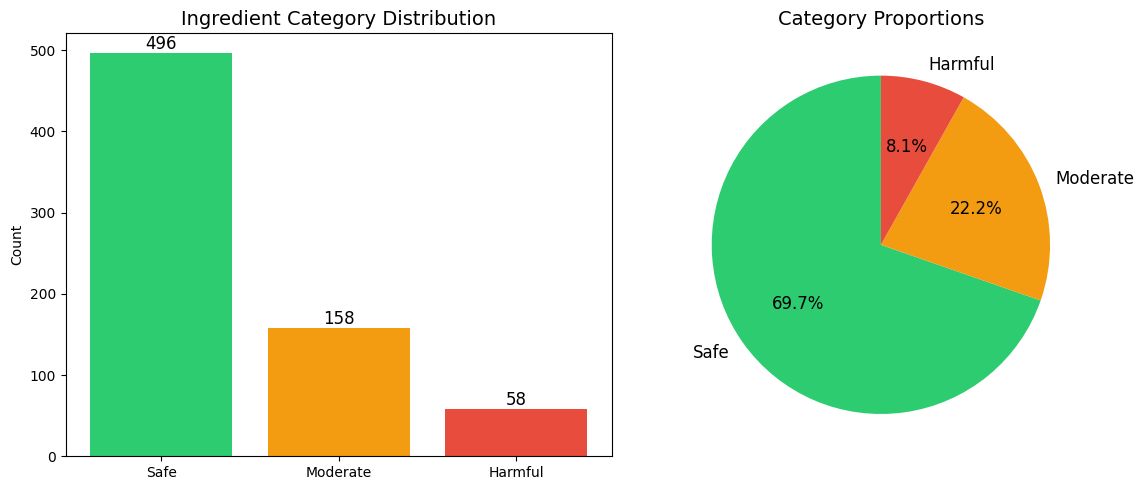

Saved: category_distribution.png


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
category_counts = df['Category'].value_counts()
colors = {'Safe': '#2ecc71', 'Moderate': '#f39c12', 'Harmful': '#e74c3c'}
bars = axes[0].bar(
    category_counts.index,
    category_counts.values,
    color=[colors.get(c, '#999') for c in category_counts.index]
)
axes[0].set_title("Ingredient Category Distribution", fontsize=14)
axes[0].set_ylabel("Count")
for bar, count in zip(bars, category_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 str(count), ha='center', fontsize=12)

# Pie chart
axes[1].pie(
    category_counts.values,
    labels=category_counts.index,
    colors=[colors.get(c, '#999') for c in category_counts.index],
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 12}
)
axes[1].set_title("Category Proportions", fontsize=14)

plt.tight_layout()
plt.savefig("category_distribution.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: category_distribution.png")

In [9]:

X = df['combined_text']
y = df['label']

# Split data: 80% train, 20% test (stratified to maintain class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")
print(f"\nTraining label distribution:\n{pd.Series(y_train).value_counts()}")

# TF-IDF Vectorization
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),   # unigrams and bigrams
    stop_words='english',
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"\nTF-IDF feature matrix shape: {X_train_tfidf.shape}")

Training set: 569 samples
Test set:     143 samples

Training label distribution:
label
2    397
1    126
0     46
Name: count, dtype: int64

TF-IDF feature matrix shape: (569, 1500)


In [10]:
classifiers = {
    "Naive Bayes": MultinomialNB(alpha=1.0),
    "SVM": SVC(kernel='linear', C=1.0, random_state=42),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=15, min_samples_split=5, random_state=42
    )
}


results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, clf in classifiers.items():
    print(f"\n{'='*60}")
    print(f"Training: {name}")
    print(f"{'='*60}")
    
    # Cross-validation
    cv_scores = cross_val_score(clf, X_train_tfidf, y_train, cv=cv, scoring='accuracy')
    print(f"Cross-validation accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

    # Train on full training set
    clf.fit(X_train_tfidf, y_train)

    # Predict on test set
    y_pred = clf.predict(X_test_tfidf)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    report = classification_report(
        y_test, y_pred,
        target_names=label_encoder.classes_,
        output_dict=True
    )

    results[name] = {
        'model': clf,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'test_accuracy': acc,
        'y_pred': y_pred,
        'report': report
    }

    print(f"Test accuracy: {acc:.4f}")
    print(f"\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))


Training: Naive Bayes
Cross-validation accuracy: 0.7452 (+/- 0.0227)
Test accuracy: 0.8252

Classification Report:
              precision    recall  f1-score   support

     Harmful       1.00      0.33      0.50        12
    Moderate       1.00      0.47      0.64        32
        Safe       0.80      1.00      0.89        99

    accuracy                           0.83       143
   macro avg       0.93      0.60      0.68       143
weighted avg       0.86      0.83      0.80       143


Training: SVM
Cross-validation accuracy: 0.8577 (+/- 0.0300)
Test accuracy: 0.9161

Classification Report:
              precision    recall  f1-score   support

     Harmful       0.73      0.67      0.70        12
    Moderate       0.93      0.78      0.85        32
        Safe       0.93      0.99      0.96        99

    accuracy                           0.92       143
   macro avg       0.86      0.81      0.83       143
weighted avg       0.91      0.92      0.91       143


Training: Dec

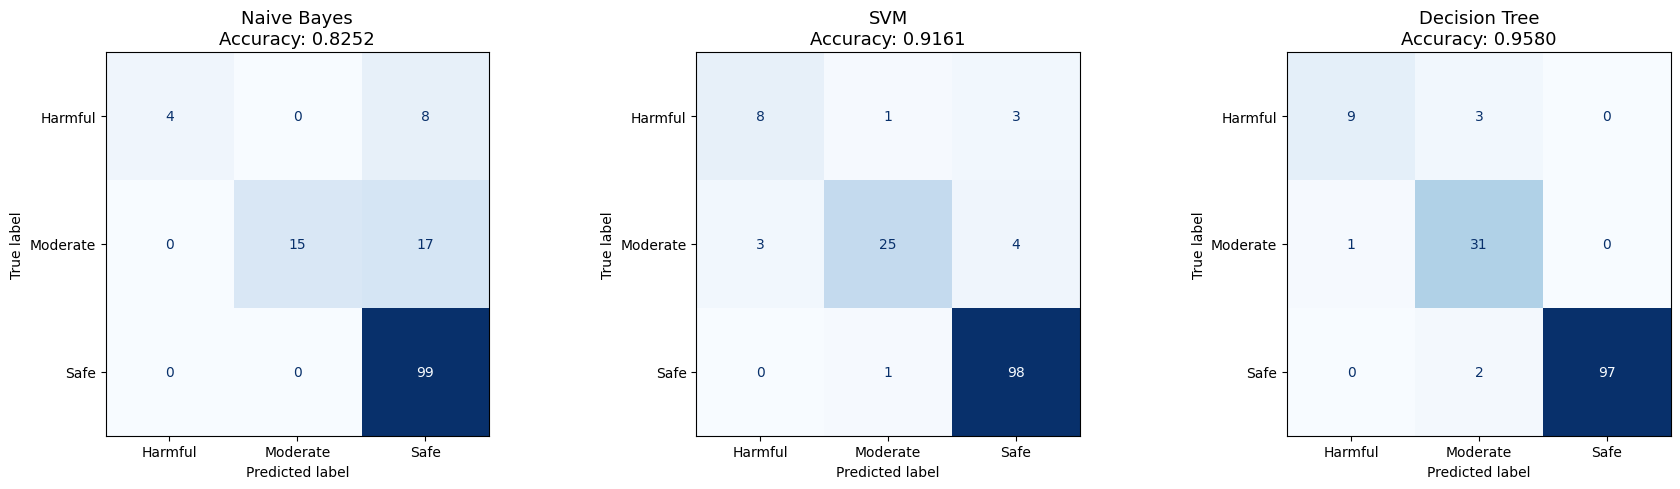

In [11]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=label_encoder.classes_
    )
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(f"{name}\nAccuracy: {res['test_accuracy']:.4f}", fontsize=13)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150, bbox_inches='tight')
plt.show()



MODEL COMPARISON SUMMARY
        Model  CV Accuracy (mean)  CV Accuracy (std)  Test Accuracy  Macro F1  Weighted F1
  Naive Bayes            0.745179           0.022724       0.825175  0.675397     0.799489
          SVM            0.857662           0.030003       0.916084  0.834631     0.913176
Decision Tree            0.915665           0.017967       0.958042  0.906581     0.957933


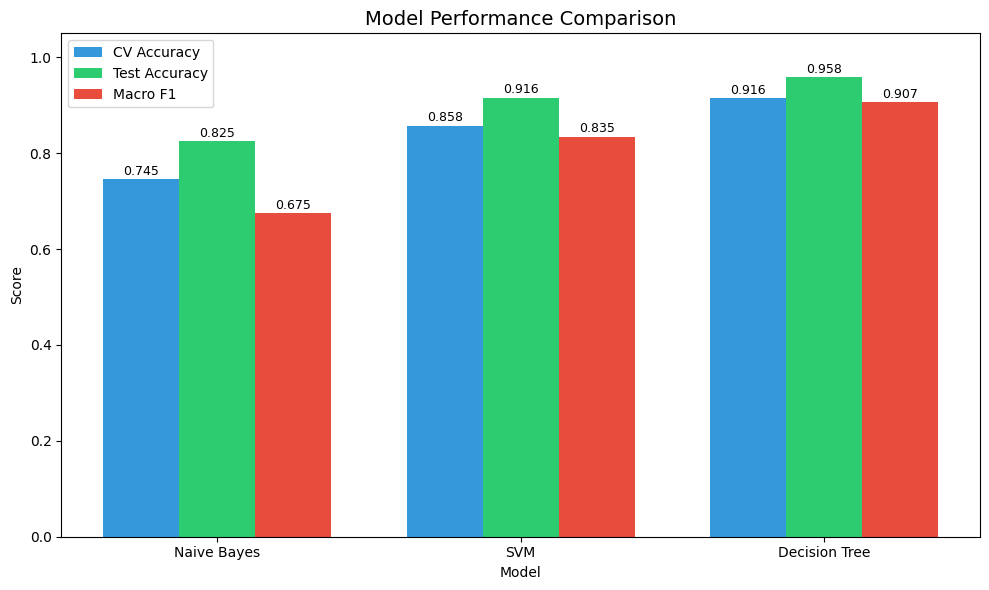

Saved: model_comparison.png

Best performing model: Decision Tree


In [12]:
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'CV Accuracy (mean)': [r['cv_mean'] for r in results.values()],
    'CV Accuracy (std)': [r['cv_std'] for r in results.values()],
    'Test Accuracy': [r['test_accuracy'] for r in results.values()],
    'Macro F1': [r['report']['macro avg']['f1-score'] for r in results.values()],
    'Weighted F1': [r['report']['weighted avg']['f1-score'] for r in results.values()],
})

print("\n" + "="*70)
print("MODEL COMPARISON SUMMARY")
print("="*70)
print(comparison_df.to_string(index=False))

# Bar chart comparison
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(comparison_df))
width = 0.25

bars1 = ax.bar(x - width, comparison_df['CV Accuracy (mean)'], width, label='CV Accuracy', color='#3498db')
bars2 = ax.bar(x, comparison_df['Test Accuracy'], width, label='Test Accuracy', color='#2ecc71')
bars3 = ax.bar(x + width, comparison_df['Macro F1'], width, label='Macro F1', color='#e74c3c')

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Model'])
ax.legend()
ax.set_ylim(0, 1.05)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width()/2, height),
                    xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: model_comparison.png")

# Select best model
best_model_name = comparison_df.loc[comparison_df['Test Accuracy'].idxmax(), 'Model']
best_model = results[best_model_name]['model']
print(f"\nBest performing model: {best_model_name}")

In [40]:

reader = easyocr.Reader(['en'], gpu=False) 

def extract_text_from_image(image_path):
 
    result = reader.readtext(image_path, detail=0, paragraph=True)
    raw_text = " ".join(result)
    print(f"[OCR] Extracted text from '{image_path}':")
    print(f"  -> {raw_text[:200]}{'...' if len(raw_text) > 200 else ''}")
    return raw_text

Using CPU. Note: This module is much faster with a GPU.


In [41]:

def parse_ingredients(raw_text):
    """
    Parse individual ingredients from OCR-extracted text.

    Handles common OCR issues and ingredient list formats:
    - Finds text after 'ingredients:' keyword
    - Splits on commas, semicolons, and periods
    - Cleans up parenthetical sub-ingredients
    - Removes noise and short tokens
    """
    text = raw_text.lower()

   
    patterns = [
        r'ingredients?\s*[:\-]\s*(.*)',
        r'contains?\s*[:\-]\s*(.*)',
    ]

    ingredient_text = ""
    for pattern in patterns:
        match = re.search(pattern, text, re.DOTALL)
        if match:
            ingredient_text = match.group(1)
            break

    # If no keyword found, use the full text
    if not ingredient_text:
        ingredient_text = text

    # Clean up the text
    # Remove parenthetical sub-ingredients but keep the main ingredient
   # NOW remove parenthetical content to get clean top-level ingredients
    sub_ingredients = _extract_sub_ingredients(ingredient_text)
    ingredient_text_clean = re.sub(r'\([^)]*\)', '', ingredient_text)

    # Spliting on commas, semicolons, periods, and 'and'
    ingredients = re.split(r'[,;.]|\band\b', ingredient_text_clean)

    # Adding the extracted sub-ingredients to the list AFTER the split
    ingredients.extend(sub_ingredients)
    # Removing common non-ingredient phrases
    stop_phrases = [
        'nutrition facts', 'serving size', 'calories', 'daily value',
        'manufactured by', 'distributed by', 'best before', 'net wt',
        'allergen', 'warning', 'storage', 'keep refrigerated'
    ]
    for phrase in stop_phrases:
        ingredient_text = ingredient_text.replace(phrase, '')

    # Split on commas, semicolons, periods, and 'and'
    ingredients = re.split(r'[,;.]|\band\b', ingredient_text)

    # Cleaning each ingredient
    cleaned = []
    for ing in ingredients:
        ing = ing.strip()
        ing = re.sub(r'[^a-z\s\-]', '', ing)  # keep only letters, spaces, hyphens
        ing = re.sub(r'\s+', ' ', ing).strip()
        if len(ing) > 2 and not ing.isdigit():
            cleaned.append(ing)

    # Removing duplicates while preserving the order
    seen = set()
    unique = []
    for ing in cleaned:
        if ing not in seen:
            seen.add(ing)
            unique.append(ing)

    print(f"[PARSER] Found {len(unique)} ingredients: {unique[:10]}{'...' if len(unique) > 10 else ''}")
    return unique


def _extract_sub_ingredients(text):
    """
    Extract sub-ingredients from parenthetical groups.

    """
    sub_ingredients = []

    # Find all parenthetical groups (handles simple nesting)
    paren_groups = _find_paren_groups(text)

    for group in paren_groups:
       
        if _is_sub_ingredient_list(group):
            
            parts = re.split(r'[,;]|\band\b', group)
            for part in parts:
                part = part.strip()
                if part and len(part) > 2:
                   
                    inner_paren = re.search(r'\(([^)]*)\)', part)
                    if inner_paren:
                        inner_content = inner_paren.group(1)
                        if _is_sub_ingredient_list(inner_content):
                            nested_parts = re.split(r'[,;]|\band\b', inner_content)
                            sub_ingredients.extend(
                                p.strip() for p in nested_parts if p.strip() and len(p.strip()) > 2
                            )
               
                        part_clean = re.sub(r'\([^)]*\)', '', part).strip()
                        if part_clean and len(part_clean) > 2:
                            sub_ingredients.append(part_clean)
                    else:
                        sub_ingredients.append(part)

    return sub_ingredients


def _find_paren_groups(text):
    """
    Find all top-level parenthetical groups in the text.
    Handles nested parentheses by tracking depth.
    """
    groups = []
    depth = 0
    start = -1

    for i, char in enumerate(text):
        if char == '(':
            if depth == 0:
                start = i + 1  # content starts after '('
            depth += 1
        elif char == ')':
            depth -= 1
            if depth == 0 and start != -1:
                groups.append(text[start:i].strip())
                start = -1

    return groups


def _is_sub_ingredient_list(inner_text):
    """
    Heuristic to determine if parenthetical content is a list of
    sub-ingredients vs. a simple descriptor.

    Sub-ingredient lists (returns True):
        "corn meal, ferrous sulfate, niacin, thiamin mononitrate"
        "milk, cheese cultures, salt, enzymes"
        "cultured cream, skim milk"
    """
    inner_text = inner_text.strip()

    if not inner_text:
        return False

    # If it contains commas, very likely a list of sub-ingredients
    if ',' in inner_text:
        return True

    # Phrases starting with descriptor words are NOT sub-ingredients
    descriptor_starters = [
        'made from', 'derived from', 'a ', 'an ', 'for ', 'as ',
        'to ', 'from ', 'used ', 'adds ', 'preserves ', 'may contain',
        'including', 'such as', 'processed with', 'with '
    ]
    for starter in descriptor_starters:
        if inner_text.startswith(starter):
            return False

    # Single E-number codes like "e260" are not sub-ingredient lists
    if re.match(r'^e\d{3,4}[a-z]?$', inner_text):
        return False

    # Short content (1-3 words) that doesn't match descriptors
    # is likely a single sub-ingredient
    words = inner_text.split()
    if 1 <= len(words) <= 4:
        return True

    return False



In [42]:

def fuzzy_match_ingredient(ingredient, known_ingredients, threshold=0.75):
    """
    Find the best matching ingredient from the known database using fuzzy matching.
    """
    best_match = None
    best_score = 0

    ingredient_lower = ingredient.lower().strip()

    for known in known_ingredients:
        known_lower = known.lower().strip()

        # Exact match
        if ingredient_lower == known_lower:
            return known, 1.0

        # Check if ingredient is a substring of a known ingredient or vice versa
        if ingredient_lower in known_lower or known_lower in ingredient_lower:
            score = 0.9
            if score > best_score:
                best_score = score
                best_match = known

        # Fuzzy matching
        score = SequenceMatcher(None, ingredient_lower, known_lower).ratio()
        if score > best_score:
            best_score = score
            best_match = known

    if best_score >= threshold:
        return best_match, best_score
    return None, 0


def classify_ingredients(ingredients_list, df, best_model, tfidf, label_encoder):
    """
    Classify a list of ingredients using both database lookup and ML model.

    Strategy:
    1. First try exact/fuzzy match against the known ingredient database.
    2. If no match found, use the trained ML model to predict the category.

    """
    known_ingredients = df['Ingredient_clean'].tolist()
    results = []

    for ingredient in ingredients_list:
        ingredient_clean = clean_text(ingredient)

        #Database lookup with fuzzy matching
        match, score = fuzzy_match_ingredient(ingredient_clean, known_ingredients)

        if match:
            row = df[df['Ingredient_clean'] == match].iloc[0]
            results.append({
                'ingredient': ingredient,
                'matched_to': row['Ingredient'],
                'category': row['Category'],
                'confidence': f"{score:.2f}",
                'method': 'Database Match'
            })
        else:
            # Also checking against synonyms
            synonym_match = False
            for _, row in df.iterrows():
                synonyms = clean_text(row['Synonyms_List'])
                if ingredient_clean in synonyms:
                    results.append({
                        'ingredient': ingredient,
                        'matched_to': row['Ingredient'],
                        'category': row['Category'],
                        'confidence': 'synonym match',
                        'method': 'Synonym Match'
                    })
                    synonym_match = True
                    break

            if not synonym_match:
                # ML model prediction
                feat = tfidf.transform([ingredient_clean])
                pred = best_model.predict(feat)
                category = label_encoder.inverse_transform(pred)[0]
                results.append({
                    'ingredient': ingredient,
                    'matched_to': 'N/A',
                    'category': category,
                    'confidence': 'ML prediction',
                    'method': 'ML Model'
                })

    return results

In [43]:

def analyze_food_label(image_path, df, best_model, tfidf, label_encoder):
    
    print("="*60)
    print(f"ANALYZING FOOD LABEL: {image_path}")
    print("="*60)

    # OCR
    print("\n[STEP 1] Extracting text with EasyOCR...")
    raw_text = extract_text_from_image(image_path)

    #  Parse ingredients
    print("\n[STEP 2] Parsing ingredients...")
    ingredients = parse_ingredients(raw_text)

    if not ingredients:
        print("No ingredients found in the image.")
        return pd.DataFrame()

    # Classify each ingredient
    print("\n[STEP 3] Classifying ingredients...")
    classifications = classify_ingredients(
        ingredients, df, best_model, tfidf, label_encoder
    )

    # Create results DataFrame
    results_df = pd.DataFrame(classifications)

    
    print("\n" + "="*60)
    print("CLASSIFICATION RESULTS")
    print("="*60)
    print(results_df.to_string(index=False))

    print("\n--- Safety Summary ---")
    summary = results_df['category'].value_counts()
    for cat, count in summary.items():
        emoji = {'Safe': 'SAFE', 'Moderate': 'CAUTION', 'Harmful': 'WARNING'}
        print(f"  [{emoji.get(cat, '?')}] {cat}: {count} ingredient(s)")

    harmful = results_df[results_df['category'] == 'Harmful']
    if not harmful.empty:
        print(f"\n  Harmful ingredients detected:")
        for _, row in harmful.iterrows():
            print(f"    - {row['ingredient']} (matched: {row['matched_to']})")

    return results_df


In [44]:

def visualize_results(results_df, title="Food Label Analysis"):

    if results_df.empty:
        print("No results to visualize.")
        return

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Pie chart of categories
    cat_counts = results_df['category'].value_counts()
    colors_map = {'Safe': '#2ecc71', 'Moderate': '#f39c12', 'Harmful': '#e74c3c'}
    pie_colors = [colors_map.get(c, '#999') for c in cat_counts.index]

    axes[0].pie(
        cat_counts.values, labels=cat_counts.index, colors=pie_colors,
        autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12}
    )
    axes[0].set_title(f"{title}\nCategory Breakdown", fontsize=13)

    ing_names = results_df['ingredient'].tolist()[:15]  # top 15
    ing_cats = results_df['category'].tolist()[:15]
    bar_colors = [colors_map.get(c, '#999') for c in ing_cats]

    y_pos = np.arange(len(ing_names))
    axes[1].barh(y_pos, [1]*len(ing_names), color=bar_colors)
    axes[1].set_yticks(y_pos)
    axes[1].set_yticklabels(ing_names, fontsize=10)
    axes[1].set_title("Ingredient Safety Classification", fontsize=13)
    axes[1].set_xlabel("Classified")
    axes[1].invert_yaxis()

    
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=c, label=l) for l, c in colors_map.items()]
    axes[1].legend(handles=legend_elements, loc='lower right')

    plt.tight_layout()
    plt.savefig("label_analysis_results.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: label_analysis_results.png")


DEMO: Manual ingredient list test

Sample text: Ingredients: Water, Sugar, High Fructose Corn Syrup, Citric Acid, Natural Flavors, Sodium Benzoate, Red 40, Aspartame, Caramel Color, Salt
[PARSER] Found 10 ingredients: ['water', 'sugar', 'high fructose corn syrup', 'citric acid', 'natural flavors', 'sodium benzoate', 'red', 'aspartame', 'caramel color', 'salt']

--- Demo Results ---
              ingredient                    matched_to category    confidence         method
                   water                         Water     Safe          1.00 Database Match
                   sugar                  Invert sugar Moderate          0.90 Database Match
high fructose corn syrup      High-fructose corn syrup Moderate          0.96 Database Match
             citric acid                   Citric acid     Safe          1.00 Database Match
         natural flavors                           N/A Moderate ML prediction       ML Model
         sodium benzoate               Sodium benzoate M

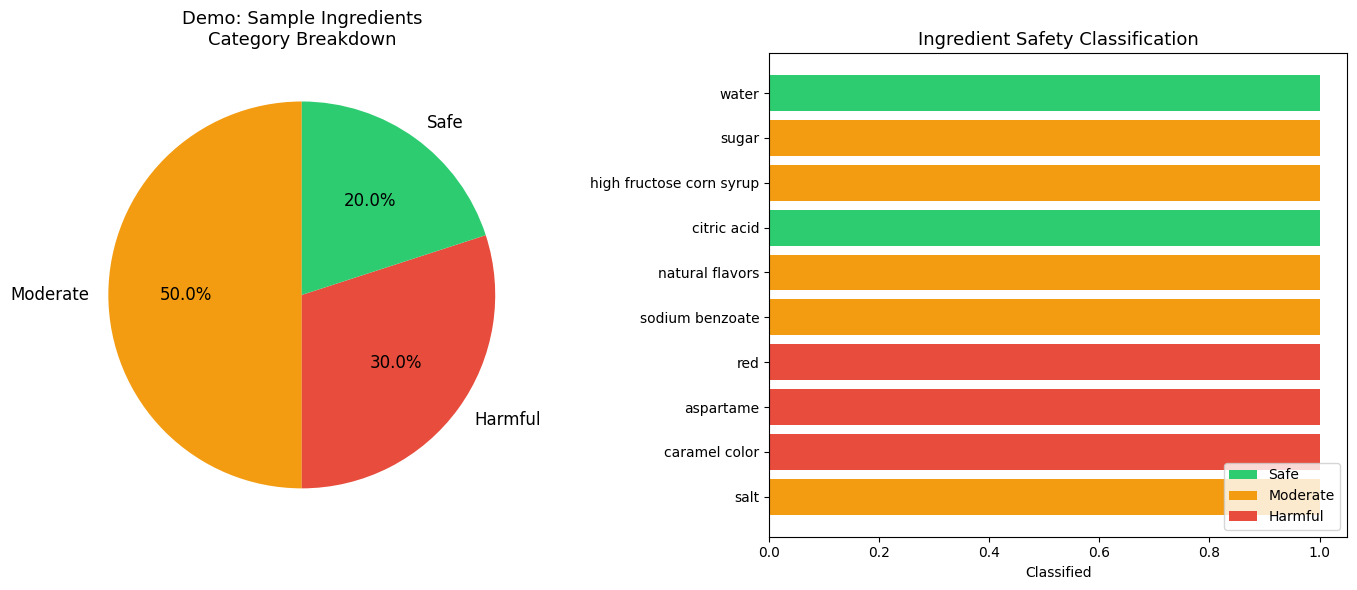

Saved: label_analysis_results.png


In [45]:
print("\n" + "="*60)
print("DEMO: Manual ingredient list test")
print("="*60)

sample_text = "Ingredients: Water, Sugar, High Fructose Corn Syrup, Citric Acid, Natural Flavors, Sodium Benzoate, Red 40, Aspartame, Caramel Color, Salt"

print(f"\nSample text: {sample_text}")
ingredients = parse_ingredients(sample_text)
classifications = classify_ingredients(ingredients, df, best_model, tfidf, label_encoder)
demo_results = pd.DataFrame(classifications)

print("\n--- Demo Results ---")
print(demo_results.to_string(index=False))
visualize_results(demo_results, title="Demo: Sample Ingredients")

ANALYZING FOOD LABEL: pure protein.png

[STEP 1] Extracting text with EasyOCR...


/Users/tanishqneela/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


[OCR] Extracted text from 'pure protein.png':
  -> INGREDIENTS: Protein Blend (Soy Protein Isolate, Whey Protein Concen - trate, Whey Protein Isolate, Milk Protein Isolate) , Hydrolyzed Collagen , Glycerine , Maltitol Syrup; Water;, Maltodextrin; Malt...

[STEP 2] Parsing ingredients...
[PARSER] Found 30 ingredients: ['protein blend soy protein isolate', 'whey protein concen - trate', 'whey protein isolate', 'milk protein isolate', 'hydrolyzed collagen', 'glycerine', 'maltitol syrup', 'water', 'maltodextrin', 'maltitol']...

[STEP 3] Classifying ingredients...

CLASSIFICATION RESULTS
                         ingredient          matched_to category    confidence         method
  protein blend soy protein isolate Soy Protein Isolate     Safe          0.90 Database Match
        whey protein concen - trate        Whey Protein     Safe          0.90 Database Match
               whey protein isolate        Whey Protein     Safe          0.90 Database Match
               milk protein isola

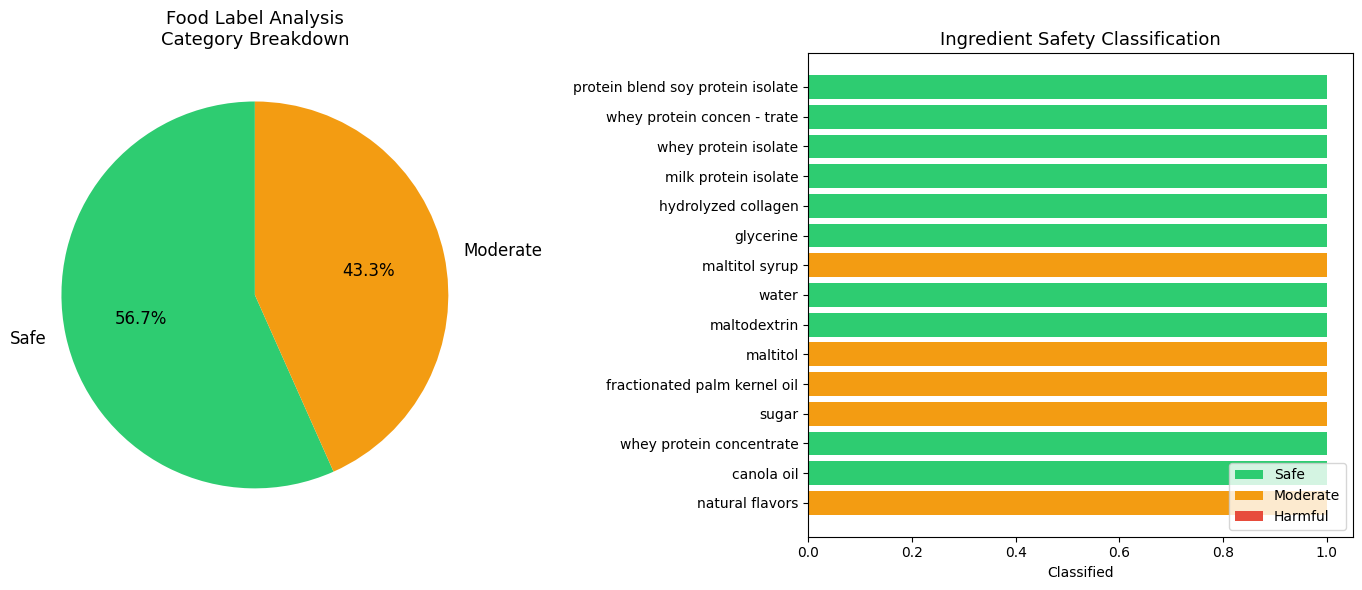

Saved: label_analysis_results.png


In [49]:
 image_path = "pure protein.png"
results_df = analyze_food_label(image_path, df, best_model, tfidf, label_encoder)
visualize_results(results_df, title="Food Label Analysis")

ANALYZING FOOD LABEL: not-so-real-ingredients-1.jpg

[STEP 1] Extracting text with EasyOCR...


/Users/tanishqneela/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


[OCR] Extracted text from 'not-so-real-ingredients-1.jpg':
  -> ingredients; Ewriched FLOUR (WHEAT FLOUR, Niacir, REOUCED IROM, THLAMIM MOMONITRATE IVITAMIR ribC?AVIM IVITAwIR FClic AcID] CoRN SYRUR SUcAR QUB AND PALMI OIL (WMth MB} FOR FRESHNESS}, CORM SYRUP SOLI...

[STEP 2] Parsing ingredients...
[PARSER] Found 38 ingredients: ['ingredients', 'ewriched flour wheat flour', 'niacir', 'reouced irom', 'thlamim momonitrate ivitamir ribcavim ivitawir fclic acid corn syrur sucar qub', 'palmi oil wmth mb for freshness', 'corm syrup solids', 'dextrose', 'high fructose corm syrup fructose', 'glycerin']...

[STEP 3] Classifying ingredients...

CLASSIFICATION RESULTS
                                                                    ingredient                   matched_to category    confidence         method
                                                                   ingredients                          N/A Moderate ML prediction       ML Model
                                         

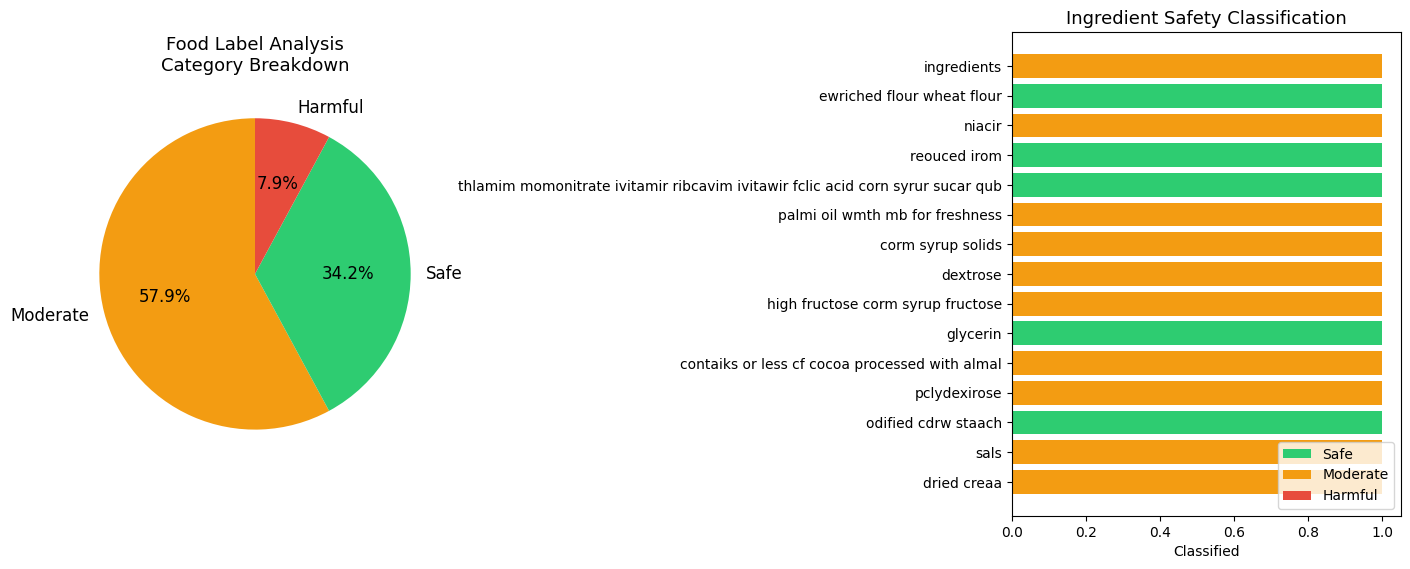

Saved: label_analysis_results.png


In [20]:
 image_path = "not-so-real-ingredients-1.jpg"
results_df = analyze_food_label(image_path, df, best_model, tfidf, label_encoder)
visualize_results(results_df, title="Food Label Analysis")

ANALYZING FOOD LABEL: image3.jpg

[STEP 1] Extracting text with EasyOCR...


/Users/tanishqneela/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


[OCR] Extracted text from 'image3.jpg':
  -> Ingredients: Rolled Oats (25.19), Candied Fruit and Nut (24%) (Candied Cranberry (149}, Almonds (109)1, Sugar; Oat Flour (0,79}, Edible Vegetable Oil (Palmolein) Rice (4.2%}, Whole Wheat (3.9%}, Rice ...

[STEP 2] Parsing ingredients...
[PARSER] Found 24 ingredients: ['rolled oats', 'candied fruit', 'nut candied cranberry', 'almonds', 'sugar', 'oat flour', 'edible vegetable oil palmolein rice', 'whole wheat', 'rice flour', 'liquid glucose']...

[STEP 3] Classifying ingredients...

CLASSIFICATION RESULTS
                                              ingredient        matched_to category    confidence         method
                                             rolled oats              Oats     Safe          0.90 Database Match
                                           candied fruit               N/A Moderate ML prediction       ML Model
                                   nut candied cranberry               N/A Moderate ML prediction       ML 

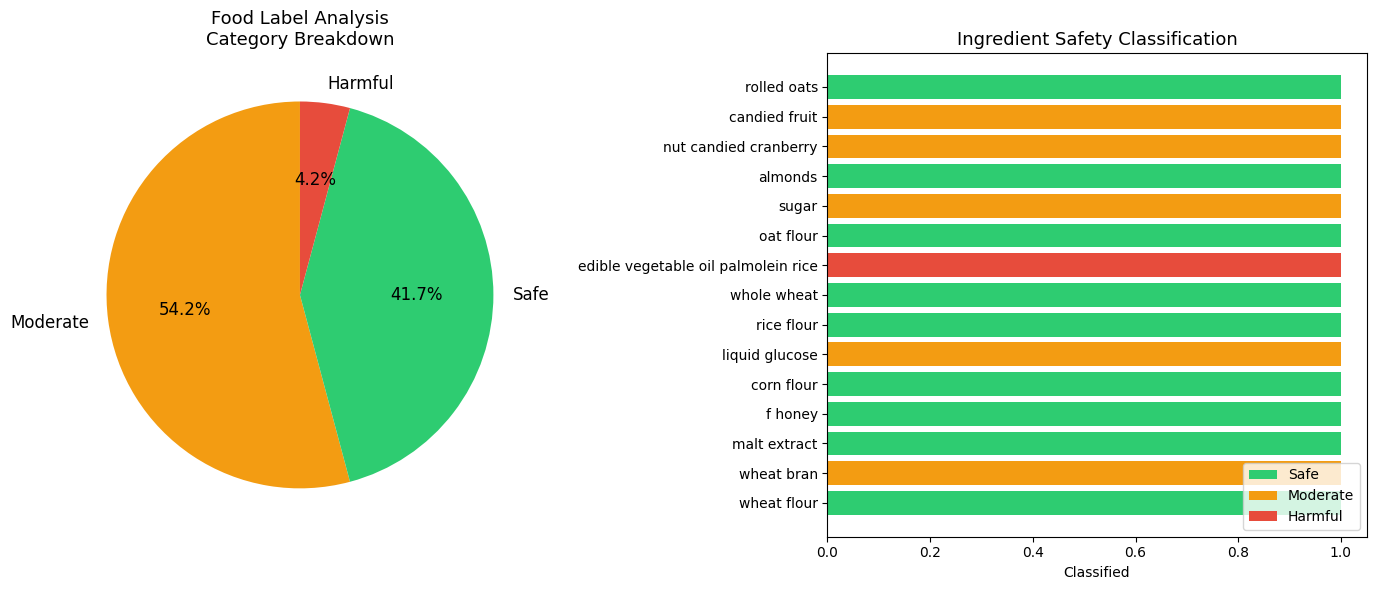

Saved: label_analysis_results.png


In [50]:
 image_path = "image3.jpg"
results_df = analyze_food_label(image_path, df, best_model, tfidf, label_encoder)
visualize_results(results_df, title="Food Label Analysis")

ANALYZING FOOD LABEL: MA6V7HQSVVCZVGWWX276LHHSAI.jpg

[STEP 1] Extracting text with EasyOCR...
[OCR] Extracted text from 'MA6V7HQSVVCZVGWWX276LHHSAI.jpg':
  -> Ingredients: Enriched Corn Meal (Corn Meal Ferrous Sulfate , Niacin , Thiamin Mononitrate Riboflavin, Folic   Acid) , Sunflower   Oil, Cheddar Cheese   (Milk, Cheese   Cultures ,  Salt,  Enzymes), Whe...

[STEP 2] Parsing ingredients...
[PARSER] Found 18 ingredients: ['enriched corn meal corn meal ferrous sulfate', 'niacin', 'thiamin mononitrate riboflavin', 'folic acid', 'sunflower oil', 'cheddar cheese milk', 'cheese cultures', 'salt', 'enzymes', 'whey']...

[STEP 3] Classifying ingredients...

CLASSIFICATION RESULTS
                                  ingredient           matched_to category    confidence         method
enriched corn meal corn meal ferrous sulfate      Ferrous sulfate     Safe          0.90 Database Match
                                      niacin  Vitamin B3 (Niacin)     Safe          0.90 Database Match
   

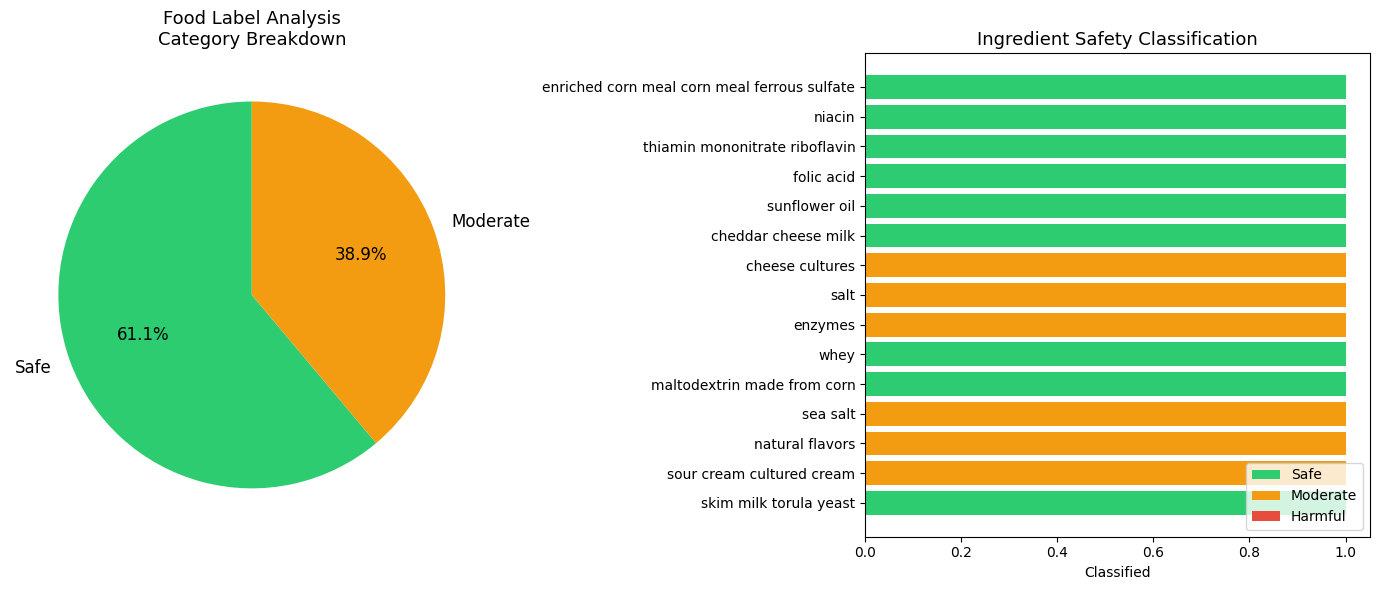

Saved: label_analysis_results.png


In [45]:
 image_path = "MA6V7HQSVVCZVGWWX276LHHSAI.jpg"
results_df = analyze_food_label(image_path, df, best_model, tfidf, label_encoder)
visualize_results(results_df, title="Food Label Analysis")

ANALYZING FOOD LABEL: Screenshot 2026-03-26 at 3.11.56 PM.png

[STEP 1] Extracting text with EasyOCR...


/Users/tanishqneela/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


[OCR] Extracted text from 'Screenshot 2026-03-26 at 3.11.56 PM.png':
  -> INGREDIENTS: Protein blend (milk protein isolate , whey protein isolate) , soluble corn fiber, cashew butter , isomalto-oligosaccharides (vegetable source) , unsweetened chocolate , erythritol, water,...

[STEP 2] Parsing ingredients...
[PARSER] Found 16 ingredients: ['protein blend milk protein isolate', 'whey protein isolate', 'soluble corn fiber', 'cashew butter', 'isomalto-oligosaccharides vegetable source', 'unsweetened chocolate', 'erythritol', 'water', 'cocoa butter', 'cocoa powder processed wilh alkali']...

[STEP 3] Classifying ingredients...

CLASSIFICATION RESULTS
                                ingredient         matched_to category    confidence         method
        protein blend milk protein isolate                N/A Moderate ML prediction       ML Model
                      whey protein isolate       Whey Protein     Safe          0.90 Database Match
                        soluble corn fiber  

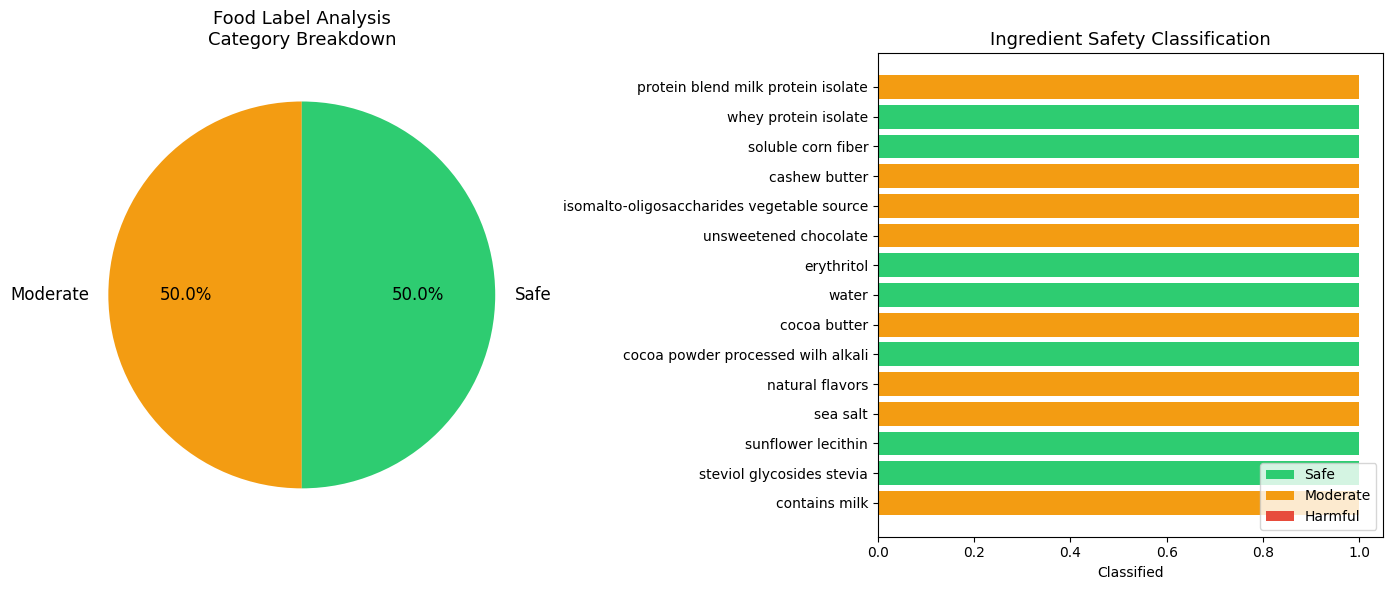

Saved: label_analysis_results.png


In [31]:
 image_path = "Screenshot 2026-03-26 at 3.11.56 PM.png"
results_df = analyze_food_label(image_path, df, best_model, tfidf, label_encoder)
visualize_results(results_df, title="Food Label Analysis")

ANALYZING FOOD LABEL: monster.png

[STEP 1] Extracting text with EasyOCR...


/Users/tanishqneela/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


[OCR] Extracted text from 'monster.png':
  -> INGREDIENTS: CARBONATED WATER, SUGAR, GLUCOSE, CITRIC ACID, NATURAL FLAVORS, TAURINE, SODIUM CITRATE, COLOR ADDED, PANAX GINSENG EXTRACT; L-CARNITINE L-TARTRATE; CAFFEINE, SORBIC ACID (PRESERVATIVE) ,...

[STEP 2] Parsing ingredients...
[PARSER] Found 23 ingredients: ['carbonated water', 'sugar', 'glucose', 'citric acid', 'natural flavors', 'taurine', 'sodium citrate', 'color added', 'panax ginseng extract', 'l-carnitine l-tartrate']...

[STEP 3] Classifying ingredients...

CLASSIFICATION RESULTS
                  ingredient                            matched_to category    confidence         method
            carbonated water                                 Water     Safe          0.90 Database Match
                       sugar                          Invert sugar Moderate          0.90 Database Match
                     glucose                         Glucose syrup Moderate          0.90 Database Match
                 citric acid    

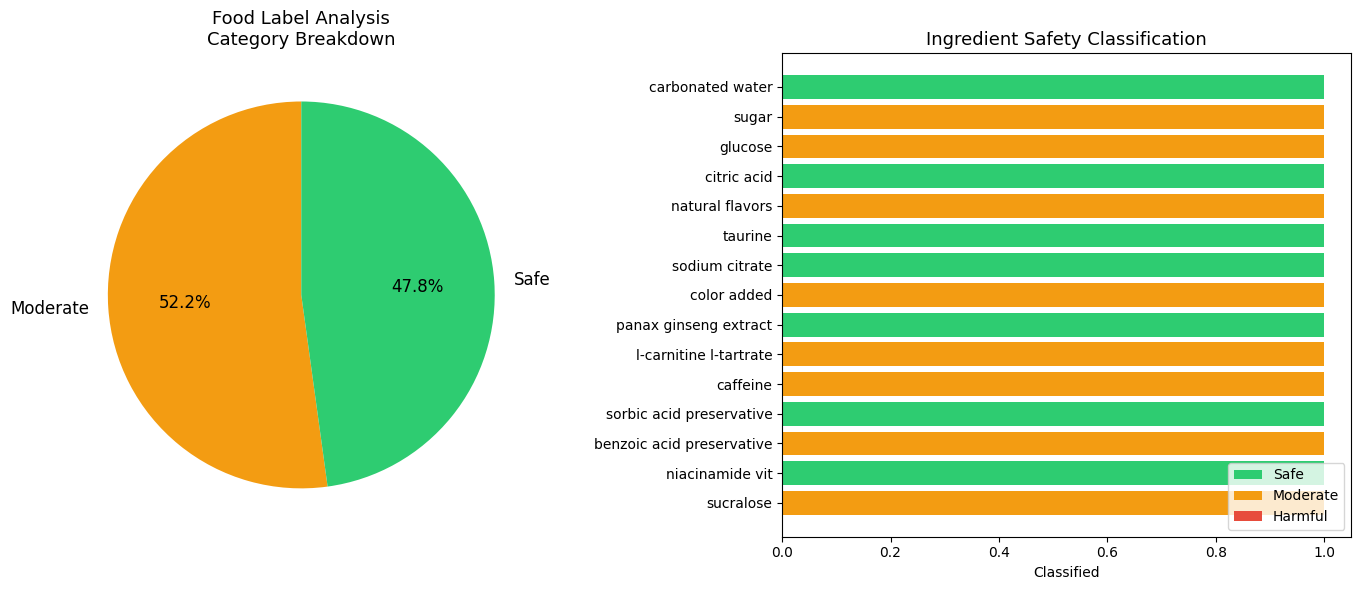

Saved: label_analysis_results.png


In [48]:
 image_path = "monster.png"
results_df = analyze_food_label(image_path, df, best_model, tfidf, label_encoder)
visualize_results(results_df, title="Food Label Analysis")

ANALYZING FOOD LABEL: maggii.png

[STEP 1] Extracting text with EasyOCR...


/Users/tanishqneela/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


[OCR] Extracted text from 'maggii.png':
  -> NOOdLCS: Refined wheat flour (Maidal. Palm oil, lodized salt; Wheat gluten, Thickeners (508 & 412), Acidity regulators (501(i) & SOO()) and Humectant (451)1: MASALA "TaSTeMakCR: Mixed Spices (26.290) ...

[STEP 2] Parsing ingredients...
[PARSER] Found 34 ingredients: ['noodlcs refined wheat flour maidal', 'palm oil', 'lodized salt', 'wheat gluten', 'thickeners', 'acidity regulators i soo', 'humectant masala tastemakcr mixed spices', 'onion powder', 'coriander powder', 'red chilli powder']...

[STEP 3] Classifying ingredients...

CLASSIFICATION RESULTS
                              ingredient           matched_to category    confidence         method
      noodlcs refined wheat flour maidal          Wheat Flour     Safe          0.90 Database Match
                                palm oil             Palm Oil Moderate          1.00 Database Match
                            lodized salt                  N/A Moderate ML prediction       ML Mod

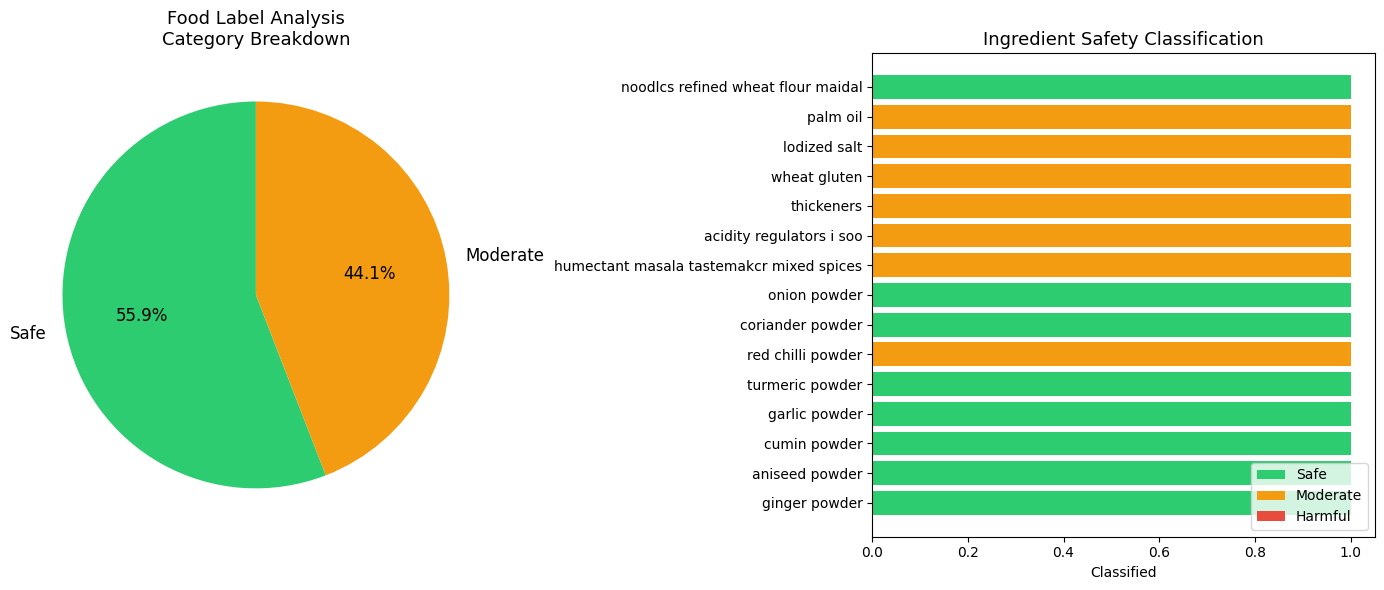

Saved: label_analysis_results.png


In [51]:
 image_path = "maggii.png"
results_df = analyze_food_label(image_path, df, best_model, tfidf, label_encoder)
visualize_results(results_df, title="Food Label Analysis")

ANALYZING FOOD LABEL: cheesecake.png

[STEP 1] Extracting text with EasyOCR...


/Users/tanishqneela/Library/Python/3.9/lib/python/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


[OCR] Extracted text from 'cheesecake.png':
  -> Chocolate Caramel Pecan Cheesecake Nutrition Facts INGREDIENTS: cream cheese Scrvings Per Conlaine (pasteurized cultured milk servind are c4ko Llice.4 3502 (1370) and cream; salt; stabilizers [xanthan...

[STEP 2] Parsing ingredients...
[PARSER] Found 60 ingredients: ['cream cheese scrvings per conlaine pasteurized cultured milk servind are cko llice', 'cream', 'salt', 'stabilizers xanthan', 'carob bcan', 'guar gumsl', 'sugar', 'graham crumb fnd t wheat flour', 'whole wheat ada flour', 'soybean oil']...

[STEP 3] Classifying ingredients...

CLASSIFICATION RESULTS
                                                                        ingredient                                        matched_to category    confidence         method
cream cheese scrvings per conlaine pasteurized cultured milk servind are cko llice                                               N/A Moderate ML prediction       ML Model
                                       

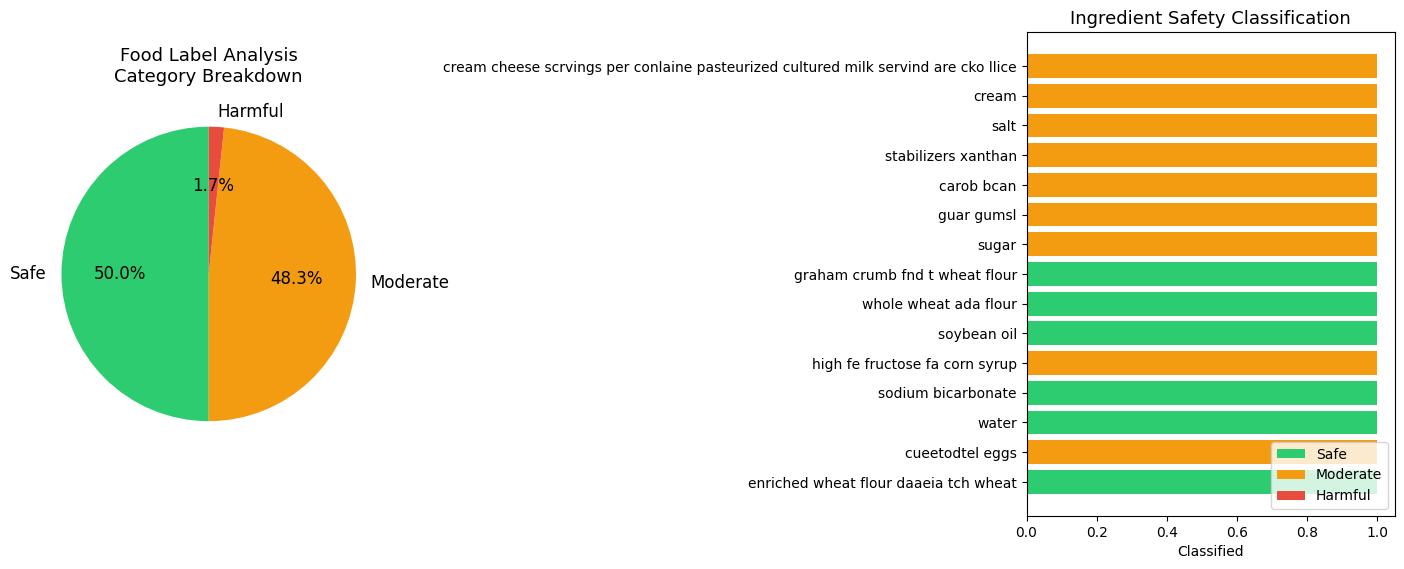

Saved: label_analysis_results.png


In [53]:
 image_path = "cheesecake.png"
results_df = analyze_food_label(image_path, df, best_model, tfidf, label_encoder)
visualize_results(results_df, title="Food Label Analysis")